In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [15]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (891, 15)

First 5 Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

Statistical Summary:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Missing Values in Each Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Missing Values Percentage:
survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


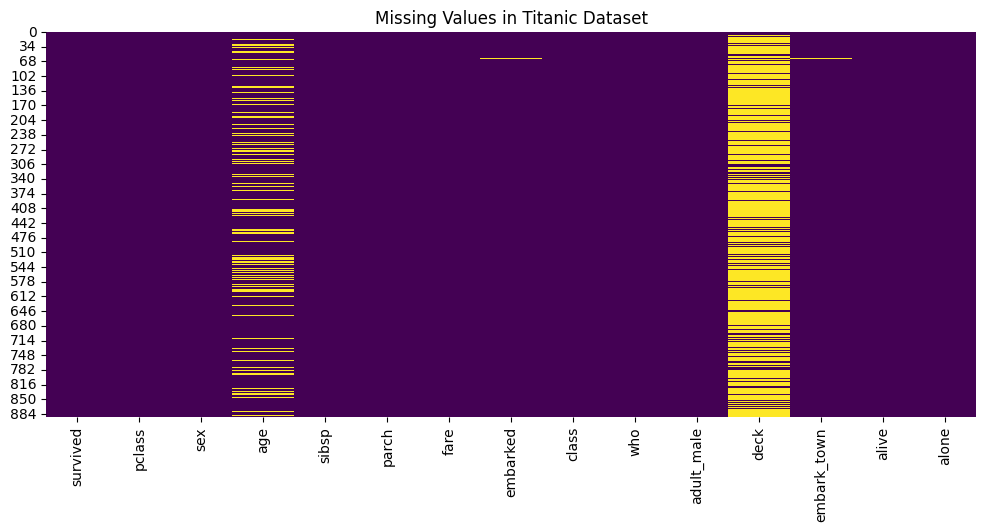

In [16]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")

plt.title("Missing Values in Titanic Dataset")
plt.show()

In [17]:
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)


df = df.drop(columns=["deck"])

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64


In [18]:
df["embark_town"] = df["embark_town"].fillna(
    df["embark_town"].mode()[0]
)

print("Missing Values After Final Cleaning:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values After Final Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Total Missing Values: 0


In [19]:
duplicates = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicates)

df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)


Number of Duplicate Rows: 118
Dataset Shape After Removing Duplicates: (773, 14)


In [20]:
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
embark_town      object
alive            object
alone              bool
dtype: object


In [21]:
df = sns.load_dataset("titanic")

df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)

df["embark_town"] = df["embark_town"].fillna(
    df["embark_town"].mode()[0]
)

df = df.drop(columns=["deck"])

print("Duplicate Rows:", df.duplicated().sum())

print("Dataset Shape:", df.shape)


Duplicate Rows: 118
Dataset Shape: (891, 14)


Survival Rate by Gender:
sex
female    74.20
male      18.89
Name: survived, dtype: float64


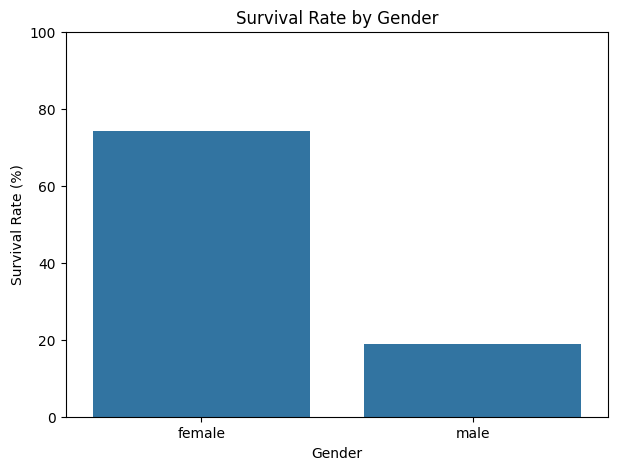

In [22]:
#Survival rate by gender

gender_survival = df.groupby("sex")["survived"].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_survival.index,
    y=gender_survival.values
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()


Survival Rate by Passenger Class:
         mean  count
pclass              
1       62.96    216
2       47.28    184
3       24.24    491


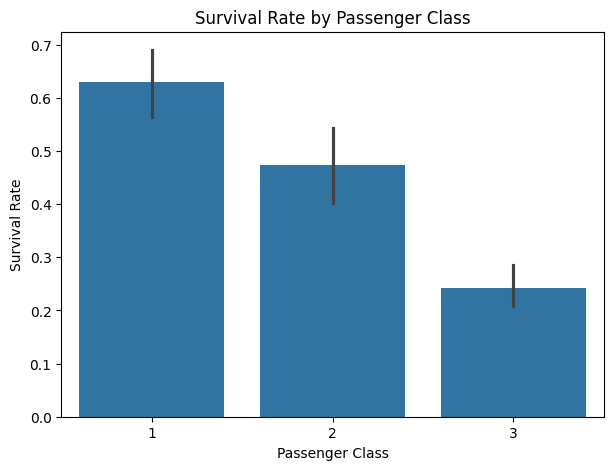

In [23]:
#Survival rate by passenger class

class_survival = df.groupby("pclass")["survived"].agg(
    ["mean", "count"]
)

class_survival["mean"] = class_survival["mean"] * 100

print("Survival Rate by Passenger Class:")
print(class_survival.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    x="pclass",
    y="survived",
    data=df
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

Survival Rate by Age Group:
age_band
Child          57.97
Teen           42.86
Adult          36.05
Middle-aged    39.06
Senior         22.73
Name: survived, dtype: float64


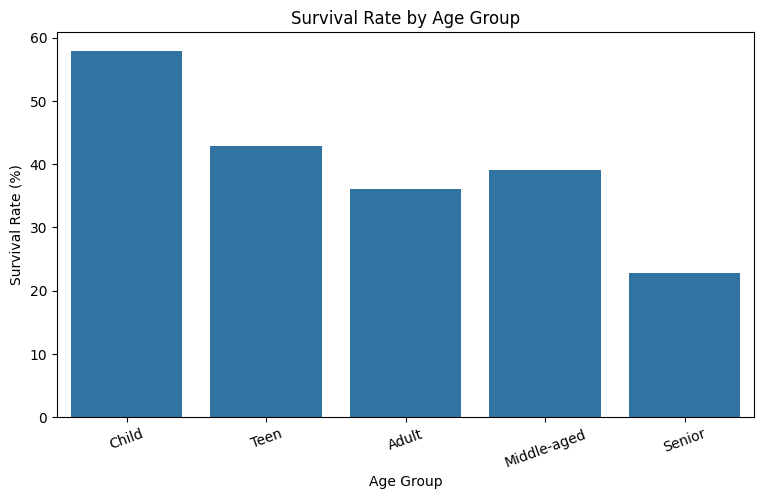

In [24]:
#Create age groups

df["age_band"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"]
)

age_survival = df.groupby(
    "age_band", observed=True
)["survived"].mean() * 100

print("Survival Rate by Age Group:")
print(age_survival.round(2))


plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_survival.index,
    y=age_survival.values
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=20)
plt.show()


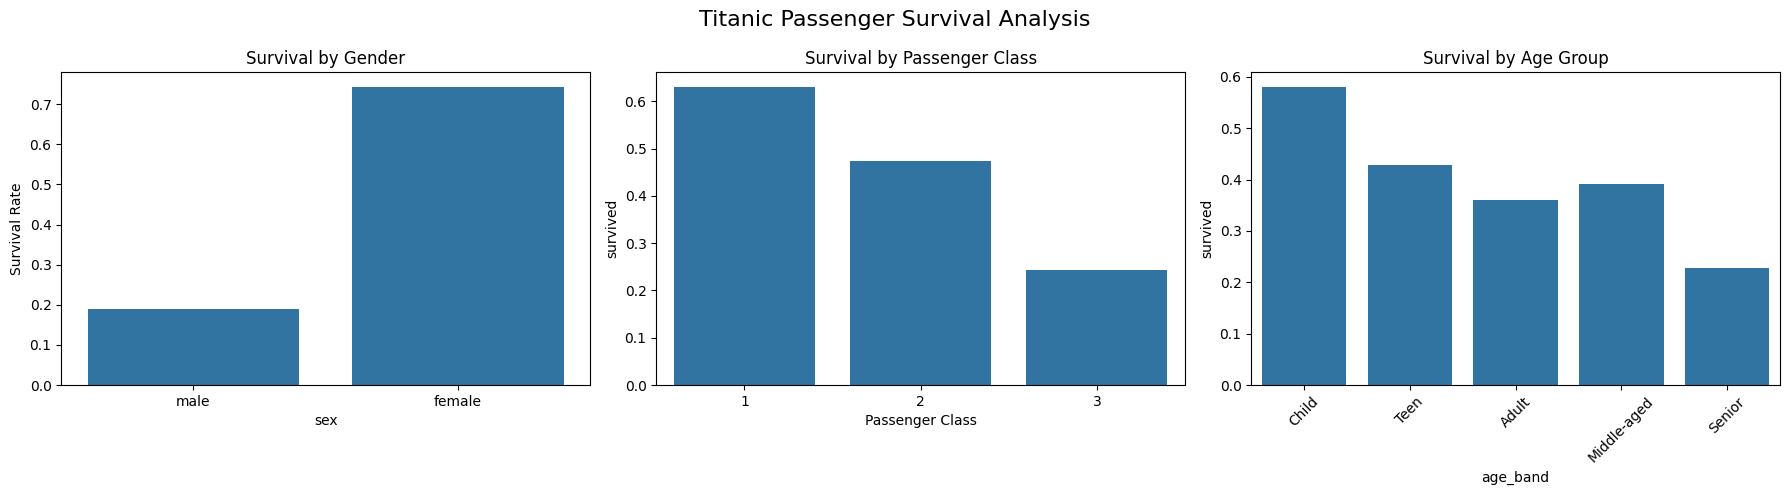

In [25]:
#Combined survival analysis

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#Gender
sns.barplot(
    x="sex", y="survived", data=df,
    ax=axes[0], errorbar=None
)
axes[0].set_title("Survival by Gender")
axes[0].set_ylabel("Survival Rate")

#Passenger class
sns.barplot(
    x="pclass", y="survived", data=df,
    ax=axes[1], errorbar=None
)
axes[1].set_title("Survival by Passenger Class")
axes[1].set_xlabel("Passenger Class")

#Age group
sns.barplot(
    x="age_band", y="survived", data=df,
    ax=axes[2], errorbar=None
)
axes[2].set_title("Survival by Age Group")
axes[2].tick_params(axis="x", rotation=45)

plt.suptitle("Titanic Passenger Survival Analysis", fontsize=16)
plt.tight_layout()
plt.show()


# Project Conclusion

The Exploratory Data Analysis (EDA) of the Titanic dataset was performed using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The analysis revealed three important findings:

1. **Gender:** Female passengers had a survival rate of 74.20%, significantly higher than male passengers, who had a survival rate of 18.89%.

2. **Passenger Class:** First-class passengers had the highest survival rate of 62.96%, while third-class passengers had the lowest survival rate of 24.24%.

3. **Age Group:** Children had the highest survival rate of 57.97%, whereas senior passengers had the lowest survival rate of 22.73%.

During data preprocessing, missing values were handled using median and mode imputation. The deck column was removed because it contained a large number of missing values. Duplicate records were identified and examined without automatically deleting them.

This project helped demonstrate how exploratory data analysis can be used to clean datasets, identify patterns, perform statistical comparisons, and communicate meaningful insights through visualizations.

**Final Conclusion:** Gender, passenger class, and age group were associated with different survival rates among Titanic passengers. EDA helped uncover these patterns and understand the dataset more effectively.